# Parallel two-Feature OMS experiment

A **Parallel** Stage makes two Features, `a` and `b`, before one shared Inspection (thesis Sec. 3.4). It is
not two machines side by side. After Inspection a part:

- **conforms** if both Features are inside their Specification Limits,
- is **scrapped** if any Feature is on its scrap side,
- otherwise is **reworked**: it goes round the Stage again and only the out-of-spec Features are re-made.
  The Rework State says which: `{a}`, `{b}` or `{a, b}`.

So the Stage is a Markov chain on the states `I` (initial), `{a}`, `{b}`, `{a, b}`, absorbing in Conform or
Scrap. Because both Features share one Process Variation, they can be **correlated**, which a serial process
(one Feature per Stage) cannot express.

1. Set the inputs in the cell below. Every other cell reads them.
2. **Run All**.

The defaults are thesis reference case **R4 (Table 3.7)**: E(PR) = 71.17 at mu = [10.537, 15.590], and
minimum production cost 46.753 at [10.128, 15.181]. Set `CASE = "R3"` for Table 3.1 (71.4287 at
[10.5115, 15.5651]). The last section compares R4 with **R5 (Table 3.5)**, the same two Features made in
two serial Stages with the same costs.

In [1]:
# ---- Inputs: change these, then Run All ----
CASE = "R4"                                  # cost preset: "R4" (Table 3.7) or "R3" (Table 3.1)

LIMITS = {"a": (8.0, 12.0), "b": (13.0, 17.0)}  # Specification Limits (L, U)
SIGMAS = {"a": 1.0, "b": 1.0}                # Process Variation (standard deviations)
RHO = 0.0                                    # correlation between a and b within the Stage
REWORK_SIDES = {"a": "upper", "b": "upper"}  # "upper", "lower" or "none" for each Feature

SELLING_PRICE = 120.0
PROCESSING_COST = 45.0                       # PC, per part entering the Stage

# Rework Cost per Rework State and Scrap Cost per state the part is scrapped from.
# State names: "I" initial, "a", "b", "ab" = both Features re-made.
PRESETS = {
    "R4": dict(rework={"a": 15.0, "b": 12.0, "ab": 27.0},          # additive: 15 + 12
               scrap={"I": 27.0, "a": 27.0, "b": 27.0, "ab": 27.0},  # a scrapped part loses both: 10 + 17
               thesis_mu={"a": 10.537, "b": 15.590}, thesis_profit=71.17),
    "R3": dict(rework={"a": 15.0, "b": 12.0, "ab": 20.0},
               scrap={"I": 8.0, "a": 9.0, "b": 11.0, "ab": 14.0},
               thesis_mu={"a": 10.5115, "b": 15.5651}, thesis_profit=71.4287),
}

# Serial comparison (R5, Table 3.5): Stage 1 makes a, Stage 2 makes b. Scrap Costs are cumulative.
SERIAL = dict(processing=(25.0, 20.0), rework=(15.0, 12.0), scrap=(10.0, 27.0),
              thesis_mu={"a": 10.466, "b": 15.591}, thesis_profit=71.41)
INSPECTION = (0.0, 0.0)                      # Inspection Cost (per Inspection, per Feature inspected), both arrangements

GRID_POINTS = 61                             # resolution of the profit and cost maps (61 x 61 evaluations)
RHO_SWEEP = (-0.8, 0.8)                      # correlation range for the sensitivity study

In [2]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import ListedColormap
from scipy.stats import multivariate_normal

from oms import CostTable, Feature, InspectionCost, MeanSettings, MultivariateNormal, ReworkSide, Sequence, Stage
from oms import evaluate_sequence, evaluate_stage, optimise_means

# Palette slots 1-3, safe for colour-blind readers in any pairing. Each colour means one outcome throughout:
# blue = rework, orange = scrap, aqua = conform; grey = processing (the fixed baseline).
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, MUTED, NEUTRAL = "#1f2328", "#6e7781", "#afb8c1"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": "#d0d7de", "grid.linewidth": 0.6, "lines.linewidth": 2,
    "legend.frameon": False, "axes.axisbelow": True,
})

## Model

In [3]:
NAMES = ("a", "b")
STATE = {"I": frozenset(), "a": frozenset({"a"}), "b": frozenset({"b"}), "ab": frozenset({"a", "b"})}
LABEL = {state: name for name, state in STATE.items()}
preset = PRESETS[CASE]


def build_stage(rho=RHO):
    features = tuple(Feature(n, *LIMITS[n], rework_side=ReworkSide(REWORK_SIDES[n])) for n in NAMES)
    reworkable = {f.name for f in features if f.reworkable}
    # Only states whose Features can all be reworked exist (a "none" Feature is always scrapped).
    states = {k: s for k, s in STATE.items() if s <= reworkable}
    return Stage(
        features=features,
        variation=MultivariateNormal([SIGMAS[n] for n in NAMES], rho),
        costs=CostTable(
            processing=PROCESSING_COST,
            rework={s: preset["rework"][k] for k, s in states.items() if s},
            scrap={s: preset["scrap"][k] for k, s in states.items()},
        ),
        inspection=InspectionCost(*INSPECTION),
    )


def mu_of(result, stage_index=0):
    return dict(result.means[stage_index].by_state[STATE["I"]])


stage = build_stage()
sequence = Sequence(stages=(stage,), selling_price=SELLING_PRICE)

print(f"Case {CASE}, rho = {RHO}, SP = {SELLING_PRICE}, PC = {PROCESSING_COST}, Inspection = {INSPECTION}")
for n, f in zip(NAMES, stage.features):
    print(f"  Feature {n}:  [{f.lower}, {f.upper}], sigma = {SIGMAS[n]}, Rework Side = {f.rework_side.value}")
print(f"  {'state':<6}{'Rework Cost':>12}{'Scrap Cost':>12}")
for s in stage.states:
    print(f"  {LABEL[s]:<6}{stage.costs.rework.get(s, float('nan')):>12}{stage.costs.scrap[s]:>12}")

Case R4, rho = 0.0, SP = 120.0, PC = 45.0, Inspection = (0.0, 0.0)
  Feature a:  [8.0, 12.0], sigma = 1.0, Rework Side = upper
  Feature b:  [13.0, 17.0], sigma = 1.0, Rework Side = upper
  state  Rework Cost  Scrap Cost
  I              nan        27.0
  a             15.0        27.0
  b             12.0        27.0
  ab            27.0        27.0


## Check against the thesis

Evaluate at the Mean Settings printed in the thesis. This only matches while the inputs are the preset's.

In [4]:
at_thesis = evaluate_stage(stage, MeanSettings.per_feature(stage, preset["thesis_mu"]))
print(f"{CASE} at mu = {list(preset['thesis_mu'].values())}")
print(f"  Expected Profit   engine {at_thesis.expected_profit(SELLING_PRICE):.4f}   thesis {preset['thesis_profit']}")

R4 at mu = [10.537, 15.59]
  Expected Profit   engine 71.1723   thesis 71.17


## Optimise the Mean Settings

In [5]:
best_profit = optimise_means(sequence)
best_cost = optimise_means(sequence, objective="production_cost")
MU_PROFIT, MU_COST = mu_of(best_profit), mu_of(best_cost)


def show(title, result, mu):
    b = result.breakdown
    print(title)
    print(f"  Mean Settings      a = {mu['a']:.4f}, b = {mu['b']:.4f}")
    print(f"  Expected Profit    {b.expected_profit:9.4f}")
    print(f"  Final Conformance  {b.final_conformance:9.4f}")
    print(f"  Production cost    {b.production_cost:9.4f}  = processing {b.processing_costs[0]:.4f}"
          f" + scrap {b.scrap_costs[0]:.4f} + rework {b.rework_costs[0]:.4f}")
    print(f"  [{result.method}, {result.n_starts} starts, success={result.success}]\n")


show("Maximum Expected Profit", best_profit, MU_PROFIT)
show("Minimum production cost", best_cost, MU_COST)

Maximum Expected Profit
  Mean Settings      a = 10.5369, b = 15.5895
  Expected Profit      71.1723
  Final Conformance     0.9888
  Production cost      47.4824  = processing 45.0000 + scrap 0.3027 + rework 2.1797
  [L-BFGS-B, 8 starts, success=True]

Minimum production cost
  Mean Settings      a = 10.1277, b = 15.1814
  Expected Profit      69.4019
  Final Conformance     0.9680
  Production cost      46.7530  = processing 45.0000 + scrap 0.8652 + rework 0.8878
  [L-BFGS-B, 8 starts, success=True]



## First-pass outcomes at the profit-optimal means

The joint distribution of (a, b) on the first pass, over the outcome regions it falls into. The probabilities
in the legend are the engine's first-pass transition probabilities from the initial state.

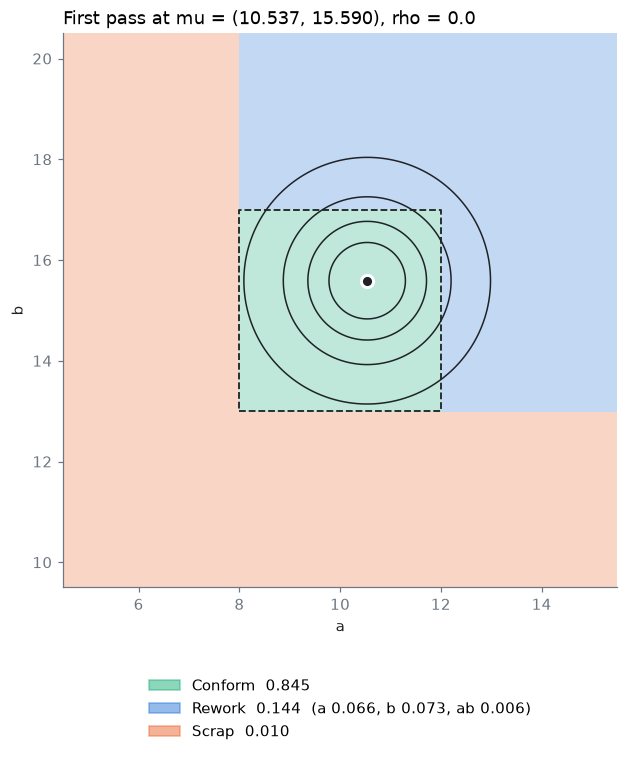

In [6]:
def classify(xa, xb):
    # 0 conform, 1 rework, 2 scrap: scrap if any Feature is on its scrap side, else rework if any is out
    status = []
    for n, x in zip(NAMES, (xa, xb)):
        lo, hi = LIMITS[n]
        side = REWORK_SIDES[n]
        rework = (x > hi) if side == "upper" else (x < lo) if side == "lower" else np.zeros_like(x, bool)
        scrap = ((x < lo) | (x > hi)) & ~rework
        status.append((rework, scrap))
    any_scrap = status[0][1] | status[1][1]
    any_rework = status[0][0] | status[1][0]
    return np.where(any_scrap, 2, np.where(any_rework, 1, 0))


def plot_first_pass(mu, ax):
    span = {n: (min(LIMITS[n][0], mu[n]) - 3.5 * SIGMAS[n], max(LIMITS[n][1], mu[n]) + 3.5 * SIGMAS[n])
            for n in NAMES}
    xa, xb = np.meshgrid(np.linspace(*span["a"], 400), np.linspace(*span["b"], 400))
    ax.pcolormesh(xa, xb, classify(xa, xb), cmap=ListedColormap([AQUA, BLUE, ORANGE]), vmin=0, vmax=2,
                  alpha=0.28, shading="auto", rasterized=True)
    cov = np.array([[SIGMAS["a"] ** 2, RHO * SIGMAS["a"] * SIGMAS["b"]],
                    [RHO * SIGMAS["a"] * SIGMAS["b"], SIGMAS["b"] ** 2]])
    density = multivariate_normal([mu["a"], mu["b"]], cov).pdf(np.dstack([xa, xb]))
    ax.contour(xa, xb, density, levels=density.max() * np.array([0.05, 0.25, 0.5, 0.75]), colors=INK,
               linewidths=1)
    (la, ua), (lb, ub) = LIMITS["a"], LIMITS["b"]
    ax.plot([la, ua, ua, la, la], [lb, lb, ub, ub, lb], color=INK, lw=1.2, ls="--")
    ax.plot(mu["a"], mu["b"], "o", ms=8, color=INK, mec="white", mew=2)

    t = evaluate_stage(stage, MeanSettings.per_feature(stage, mu)).transitions[STATE["I"]]
    handles = [plt.Rectangle((0, 0), 1, 1, color=c, alpha=0.5) for c in (AQUA, BLUE, ORANGE)]
    rework_text = ", ".join(f"{LABEL[s]} {p:.3f}" for s, p in t.rework.items())
    ax.legend(handles, [f"Conform  {t.conform:.3f}", f"Rework  {sum(t.rework.values()):.3f}  ({rework_text})",
                        f"Scrap  {t.scrap:.3f}"], loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=1)
    ax.set_xlim(span["a"]); ax.set_ylim(span["b"])
    ax.set_xlabel("a"); ax.set_ylabel("b"); ax.set_aspect("equal"); ax.grid(False)


fig, ax = plt.subplots(figsize=(6.5, 7.5))
plot_first_pass(MU_PROFIT, ax)
ax.set_title(f"First pass at mu = ({MU_PROFIT['a']:.3f}, {MU_PROFIT['b']:.3f}), rho = {RHO}", loc="left")
plt.show()

## The rework loop

Expected visits to each state per part started (m_{I,j}; the initial state is always visited once), and where
a part goes next from each state.

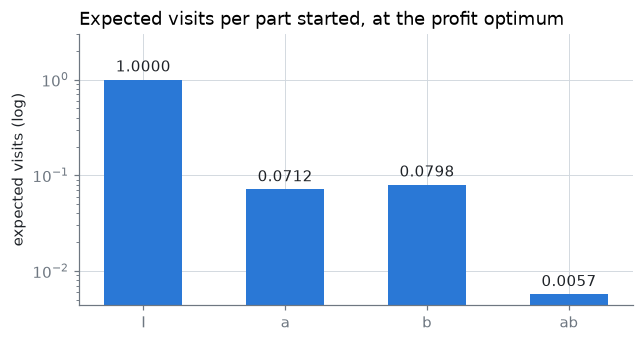

from    Conform    Scrap     -> a     -> b    -> ab
I        0.8452   0.0104   0.0657   0.0731   0.0057
a        0.9227   0.0056   0.0717   0.0000   0.0000
b        0.9160   0.0048   0.0000   0.0792   0.0000
ab       0.8452   0.0104   0.0657   0.0731   0.0057

Final Conformance 0.9888, scrap probability 0.0112


In [7]:
r = evaluate_stage(stage, MeanSettings.per_feature(stage, MU_PROFIT))
states = list(r.states)

fig, ax = plt.subplots(figsize=(6.5, 3.2))
visits = [r.visits[s] for s in states]
bars = ax.bar([LABEL[s] for s in states], visits, color=BLUE, width=0.55)
ax.bar_label(bars, labels=[f"{v:.4f}" for v in visits], padding=3, color=INK)
ax.set_yscale("log")
ax.set_ylim(top=3)
ax.set_ylabel("expected visits (log)")
ax.set_title("Expected visits per part started, at the profit optimum", loc="left")
plt.show()

header = "".join(f"{'-> ' + LABEL[s]:>9}" for s in states if s)
print(f"{'from':<6}{'Conform':>9}{'Scrap':>9}{header}")
for s in states:
    t = r.transitions[s]
    row = "".join(f"{t.rework.get(d, 0.0):9.4f}" for d in states if d)
    print(f"{LABEL[s]:<6}{t.conform:9.4f}{t.scrap:9.4f}{row}")
print(f"\nFinal Conformance {r.final_conformance:.4f}, scrap probability {r.scrap_probability:.4f}")

## Profit and cost landscapes

Evaluate the Stage over a grid of (mu_a, mu_b) inside the Specification Limits. The dot is the profit optimum,
the cross the production-cost optimum.

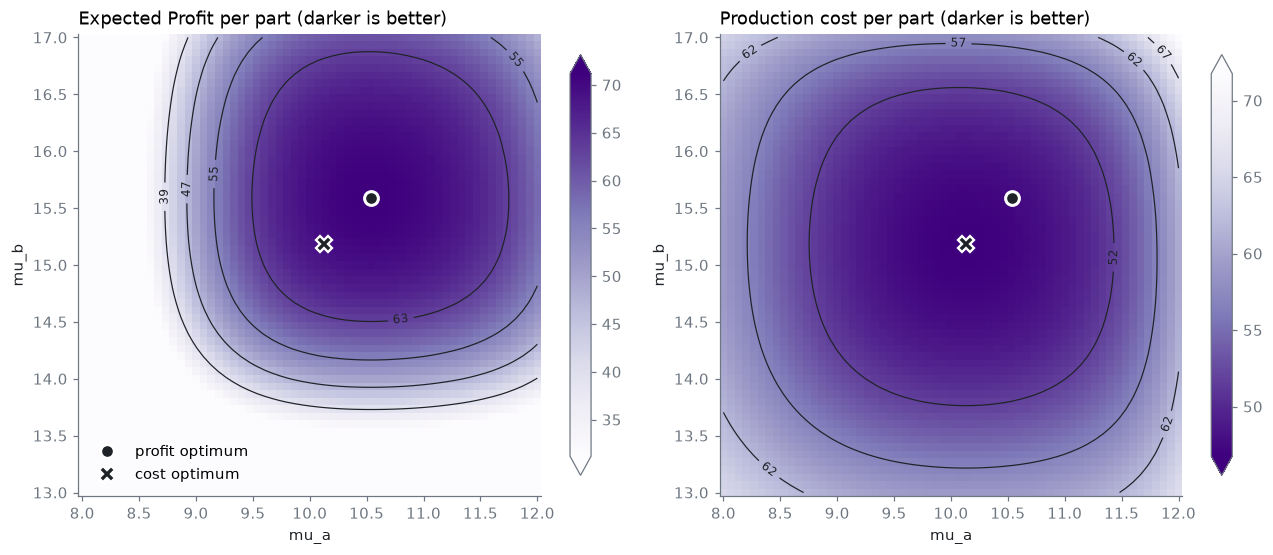

In [8]:
grid_a = np.linspace(*LIMITS["a"], GRID_POINTS)
grid_b = np.linspace(*LIMITS["b"], GRID_POINTS)
profit_map = np.empty((GRID_POINTS, GRID_POINTS))
cost_map = np.empty_like(profit_map)
for j, mb in enumerate(grid_b):
    for i, ma in enumerate(grid_a):
        res = evaluate_stage(stage, MeanSettings.per_feature(stage, {"a": float(ma), "b": float(mb)}))
        profit_map[j, i] = res.expected_profit(SELLING_PRICE)
        cost_map[j, i] = res.production_cost

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
panels = [
    (axes[0], profit_map, "Purples", (np.nanmax(profit_map) - 40, np.nanmax(profit_map)),
     "Expected Profit per part (darker is better)"),
    (axes[1], cost_map, "Purples_r", (np.nanmin(cost_map), np.nanmin(cost_map) + 25),
     "Production cost per part (darker is better)"),
]
for ax, z, cmap, (lo, hi), title in panels:
    mesh = ax.pcolormesh(grid_a, grid_b, np.clip(z, lo, hi), cmap=cmap, vmin=lo, vmax=hi, shading="auto",
                         rasterized=True)
    lines = ax.contour(grid_a, grid_b, z, levels=np.linspace(lo, hi, 6)[1:-1], colors=INK, linewidths=0.8)
    ax.clabel(lines, fmt="%.0f", fontsize=8)
    fig.colorbar(mesh, ax=ax, shrink=0.85, extend="both")
    ax.plot(MU_PROFIT["a"], MU_PROFIT["b"], "o", ms=9, color=INK, mec="white", mew=2, label="profit optimum")
    ax.plot(MU_COST["a"], MU_COST["b"], "X", ms=10, color=INK, mec="white", mew=1.5, label="cost optimum")
    ax.set_title(title, loc="left"); ax.set_xlabel("mu_a"); ax.set_ylabel("mu_b"); ax.grid(False)
    ax.set_aspect("equal")
axes[0].legend(loc="lower left")
plt.tight_layout()
plt.show()

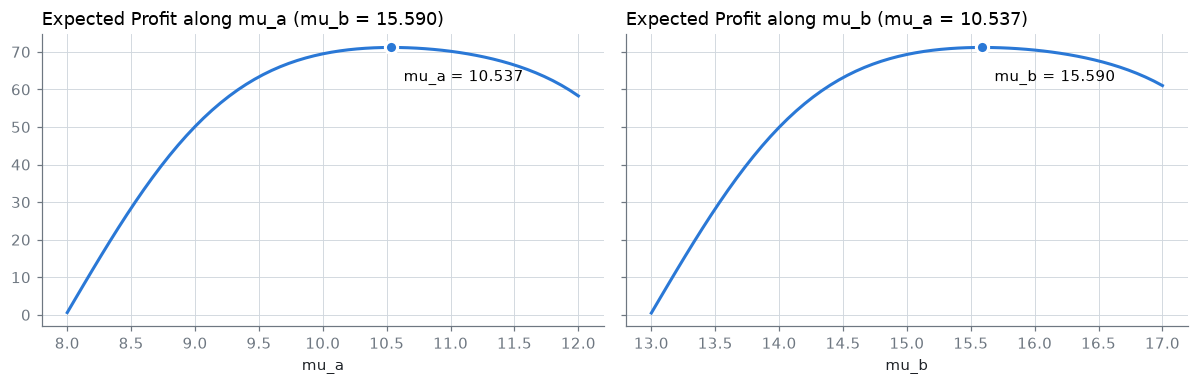

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, n, other, grid in ((axes[0], "a", "b", grid_a), (axes[1], "b", "a", grid_b)):
    values = [evaluate_stage(stage, MeanSettings.per_feature(stage, {n: float(m), other: MU_PROFIT[other]}))
              .expected_profit(SELLING_PRICE) for m in grid]
    ax.plot(grid, values, color=BLUE)
    ax.plot(MU_PROFIT[n], best_profit.breakdown.expected_profit, "o", ms=8, color=BLUE, mec="white", mew=2)
    ax.annotate(f"mu_{n} = {MU_PROFIT[n]:.3f}", (MU_PROFIT[n], best_profit.breakdown.expected_profit),
                xytext=(8, -22), textcoords="offset points")
    ax.set_title(f"Expected Profit along mu_{n} (mu_{other} = {MU_PROFIT[other]:.3f})", loc="left")
    ax.set_xlabel(f"mu_{n}")
plt.tight_layout()
plt.show()

## Sensitivity: correlation between the Features

Re-optimise for each rho in `RHO_SWEEP`. Correlation changes how often a and b go out of spec together, and so
the mix between single-Feature rework (`{a}`, `{b}`) and the combined `{a, b}` rework. With the R4 defaults,
profit is lowest near rho = 0 and rises with correlation of either sign, but only by a few tenths per part.

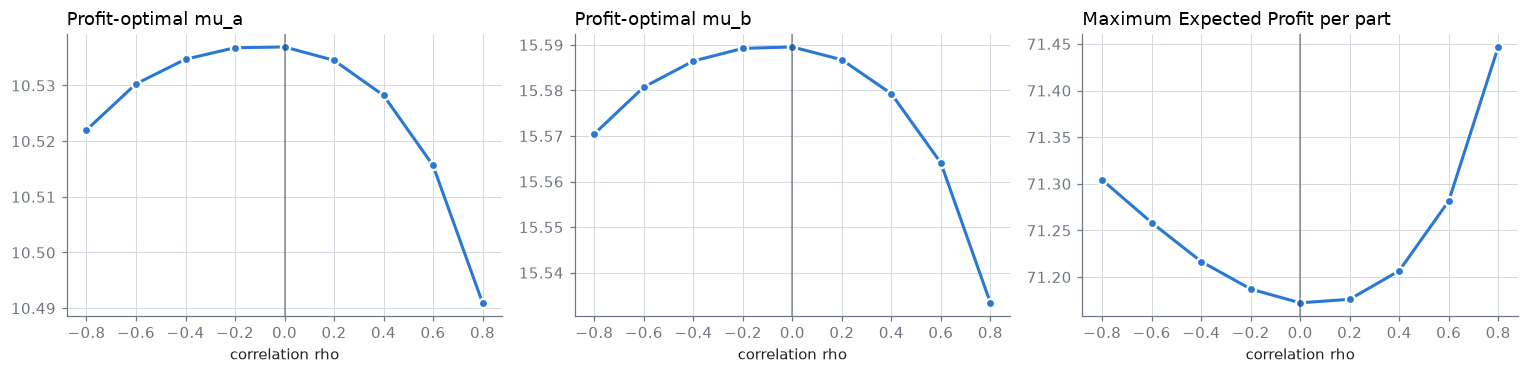

rho -0.8   mu* = (10.5220, 15.5705)   E(PR) 71.3042
rho -0.6   mu* = (10.5303, 15.5807)   E(PR) 71.2583
rho -0.4   mu* = (10.5347, 15.5864)   E(PR) 71.2166
rho -0.2   mu* = (10.5368, 15.5892)   E(PR) 71.1871
rho +0.0   mu* = (10.5369, 15.5895)   E(PR) 71.1723
rho +0.2   mu* = (10.5345, 15.5867)   E(PR) 71.1761
rho +0.4   mu* = (10.5282, 15.5793)   E(PR) 71.2067
rho +0.6   mu* = (10.5156, 15.5641)   E(PR) 71.2814
rho +0.8   mu* = (10.4910, 15.5334)   E(PR) 71.4467


In [10]:
rhos = np.linspace(*RHO_SWEEP, 9)
runs = [optimise_means(Sequence(stages=(build_stage(rho),), selling_price=SELLING_PRICE)) for rho in rhos]
opt = [mu_of(run) for run in runs]

fig, axes = plt.subplots(1, 3, figsize=(14, 3.5), sharex=True)
for ax, n in zip(axes[:2], NAMES):
    ax.plot(rhos, [m[n] for m in opt], "o-", ms=6, color=BLUE, mec="white", mew=1.5)
    ax.set_title(f"Profit-optimal mu_{n}", loc="left")
axes[2].plot(rhos, [run.breakdown.expected_profit for run in runs], "o-", ms=6, color=BLUE, mec="white", mew=1.5)
axes[2].set_title("Maximum Expected Profit per part", loc="left")
for ax in axes:
    ax.axvline(RHO, color=INK, lw=1, alpha=0.5)
    ax.set_xlabel("correlation rho")
plt.tight_layout()
plt.show()

for rho, m, run in zip(rhos, opt, runs):
    print(f"rho {rho:+.1f}   mu* = ({m['a']:.4f}, {m['b']:.4f})   E(PR) {run.breakdown.expected_profit:.4f}")

## Parallel vs serial

The same two Features made in two serial Stages (thesis R5, Table 3.5): Stage 1 makes and inspects `a`, then
Stage 2 makes and inspects `b`. Only parts that pass Stage 1 reach Stage 2, and a part scrapped at Stage 2 has
lost both Features (Scrap Cost 27 = 10 + 17). With the R4 preset the costs match, so the difference is the
arrangement alone. Serial Stages hold one Feature each, so they cannot carry the correlation `RHO`.

Serial processing cost is below 25 + 20 = 45 because parts scrapped at Stage 1 never pay for Stage 2. Set
`INSPECTION` to a non-zero per-Inspection cost to see the serial arrangement pay for its second Inspection.

R5 check at thesis mu: engine 71.4120, thesis 71.41

                         mu_a     mu_b     E(PR)   E(PR)-I     f_C  process   scrap  rework  inspect
Parallel (1 Stage)    10.5369  15.5895   71.1723   71.1723  0.9888  45.0000  0.3027  2.1797   0.0000
Serial (2 Stages)     10.4658  15.5915   71.4120   71.4120  0.9876  44.8542  0.2120  2.0285   0.0000


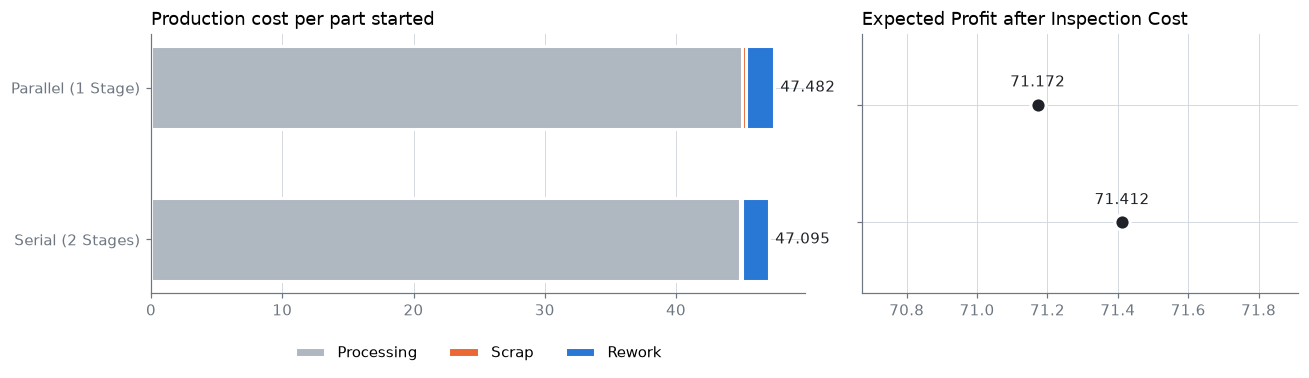

In [11]:
def serial_stage(i, n):
    x = frozenset({n})
    return Stage(
        features=(Feature(n, *LIMITS[n], rework_side=ReworkSide(REWORK_SIDES[n])),),
        variation=MultivariateNormal([SIGMAS[n]]),
        costs=CostTable(processing=SERIAL["processing"][i],
                        rework={x: SERIAL["rework"][i]} if REWORK_SIDES[n] != "none" else {},
                        scrap={STATE["I"]: SERIAL["scrap"][i]} | ({x: SERIAL["scrap"][i]} if REWORK_SIDES[n] != "none" else {})),
        inspection=InspectionCost(*INSPECTION),
    )


serial = Sequence(stages=(serial_stage(0, "a"), serial_stage(1, "b")), selling_price=SELLING_PRICE)
serial_best = optimise_means(serial)
mu_serial = {"a": mu_of(serial_best, 0)["a"], "b": mu_of(serial_best, 1)["b"]}
at_thesis = evaluate_sequence(serial, [MeanSettings.per_feature(s, {n: SERIAL["thesis_mu"][n]})
                                       for s, n in zip(serial.stages, NAMES)])
print(f"R5 check at thesis mu: engine {at_thesis.expected_profit:.4f}, thesis {SERIAL['thesis_profit']}\n")

rows = {"Parallel (1 Stage)": (best_profit.breakdown, MU_PROFIT), "Serial (2 Stages)": (serial_best.breakdown, mu_serial)}
print(f"{'':<20}{'mu_a':>9}{'mu_b':>9}{'E(PR)':>10}{'E(PR)-I':>10}{'f_C':>8}{'process':>9}{'scrap':>8}{'rework':>8}{'inspect':>9}")
for name, (b, mu) in rows.items():
    print(f"{name:<20}{mu['a']:9.4f}{mu['b']:9.4f}{b.expected_profit:10.4f}{b.expected_profit_after_inspection:10.4f}"
          f"{b.final_conformance:8.4f}{sum(b.processing_costs):9.4f}{sum(b.scrap_costs):8.4f}"
          f"{sum(b.rework_costs):8.4f}{b.inspection_cost:9.4f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), gridspec_kw={"width_ratios": [3, 2]})
names = list(rows)
parts = [("Processing", NEUTRAL, lambda b: sum(b.processing_costs)), ("Scrap", ORANGE, lambda b: sum(b.scrap_costs)),
         ("Rework", BLUE, lambda b: sum(b.rework_costs))]
left = np.zeros(len(names))
for label, colour, get in parts:
    widths = np.array([get(rows[n][0]) for n in names])
    axes[0].barh(names, widths, left=left, color=colour, label=label, edgecolor="white", linewidth=2, height=0.55)
    left += widths
for y, total in enumerate(left):
    axes[0].annotate(f"{total:.3f}", (total, y), xytext=(4, 0), textcoords="offset points", va="center", color=INK)
axes[0].set_title("Production cost per part started", loc="left")
axes[0].legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=3)
axes[0].invert_yaxis()

profits = [rows[n][0].expected_profit_after_inspection for n in names]
# Dots, not bars: the gap is small next to the profit itself, and a bar axis must start at zero.
axes[1].plot(profits, names, "o", ms=10, color=INK, mec="white", mew=2)
for y, p in enumerate(profits):
    axes[1].annotate(f"{p:.3f}", (p, y), xytext=(0, 12), textcoords="offset points", ha="center", color=INK)
pad = max(0.5, abs(profits[0] - profits[1]))
axes[1].set_xlim(min(profits) - pad, max(profits) + pad)
axes[1].set_ylim(1.6, -0.6)
axes[1].set_title("Expected Profit after Inspection Cost", loc="left")
axes[1].set_yticks([0, 1], labels=[])
plt.tight_layout()
plt.show()